## Lab 1 — Intro to Behavioral TV Data
# Name:Yeromenko Marharyta
# Group: КМ-42

### Setup

In [34]:
# %%
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

### Task 1.1 - Panel and universe

In [35]:
# %%
telecasts = len(programs)
distinct_programs = programs['program_name'].nunique()
networks = programs['network_code'].nunique()

# Determine in-tab respondents in October
in_tab_households = daily_weights[daily_weights['resp_type'] == 'H']['respondent_id'].nunique()
in_tab_persons = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])]['respondent_id'].nunique()

# Daily averages
daily_counts = daily_weights.groupby('broadcast_date').agg(
    h_count=('respondent_id', lambda x: x[daily_weights.loc[x.index, 'resp_type'] == 'H'].nunique()),
    p_count=('respondent_id', lambda x: x[daily_weights.loc[x.index, 'resp_type'].isin(['R', 'L'])].nunique()),
    h_weight=('weight', lambda x: x[daily_weights.loc[x.index, 'resp_type'] == 'H'].sum()),
    p_weight=('weight', lambda x: x[daily_weights.loc[x.index, 'resp_type'].isin(['R', 'L'])].sum())
)

print("Telecasts:", telecasts)
print("Programs:", distinct_programs)
print("Networks:", networks)
print("Households in panel:", in_tab_households)
print("Persons in panel:", in_tab_persons)
print("Households in-tab, average day:", int(daily_counts['h_count'].mean()))
print("Persons in-tab, average day:", int(daily_counts['p_count'].mean()))
print(f"US TV households represented, average day (M): {daily_counts['h_weight'].mean() / 1e6:.2f}")
print(f"US persons represented, average day (M): {daily_counts['p_weight'].mean() / 1e6:.2f}")

Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878
Persons in-tab, average day: 9268
US TV households represented, average day (M): 125.80
US persons represented, average day (M): 317.28


**Answer:** The viewer_attributes file has all respondents who were in the panel at any time. But the daily_weights (in-tab data) only shows people whose meters actually worked and sent data on specific days in October.

### Task 1.2 - Average audience by hour of day

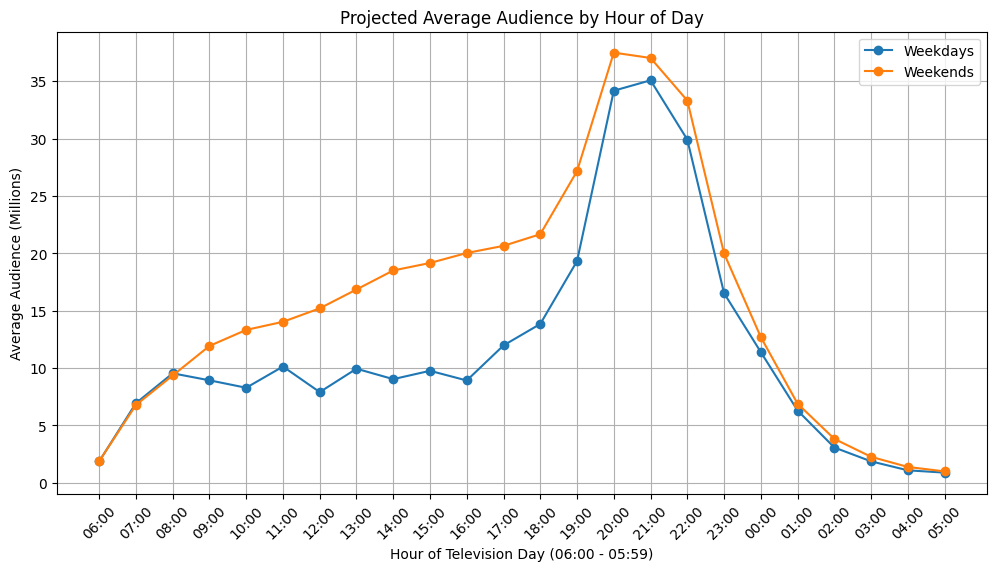

Peak hour, weekdays: 21
Peak hour, weekends: 20


In [36]:
# %%
# Filter only persons (excluding S guests)
v_persons = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()

# Add broadcast_date to determine weekdays/weekends (06:00 - 05:59)
v_persons['broadcast_date'] = (v_persons['start_ts'] - pd.Timedelta(hours=6)).dt.date
v_persons['is_weekend'] = pd.to_datetime(v_persons['broadcast_date']).dt.dayofweek >= 5

# Calculate overlap for each hour using a loop (maybe not the most efficient way, but it works)
hourly_data = []
for hour in range(24):
    # Adjust for broadcast day (06:00 to 05:59 next day)
    if hour >= 6:
        h_start_time = pd.to_datetime(v_persons['broadcast_date']) + pd.Timedelta(hours=hour)
    else:
        h_start_time = pd.to_datetime(v_persons['broadcast_date']) + pd.Timedelta(days=1, hours=hour)
        
    h_end_time = h_start_time + pd.Timedelta(hours=1)
    
    overlap_start = np.maximum(v_persons['start_ts'], h_start_time)
    overlap_end = np.minimum(v_persons['end_ts'], h_end_time)
    
    minutes = (overlap_end - overlap_start).dt.total_seconds() / 60
    minutes = np.maximum(minutes, 0)
    
    weighted_minutes = minutes * v_persons['weight']
    
    # Group by date
    daily_hw = pd.DataFrame({'broadcast_date': v_persons['broadcast_date'], 'w_mins': weighted_minutes})
    daily_hw = daily_hw[daily_hw['w_mins'] > 0]
    
    for date, group in daily_hw.groupby('broadcast_date'):
        hourly_data.append({'date': date, 'hour': hour, 'weighted_minutes': group['w_mins'].sum()})

hourly_df = pd.DataFrame(hourly_data)
hourly_df['is_weekend'] = pd.to_datetime(hourly_df['date']).dt.dayofweek >= 5

# Count unique weekdays and weekends in October
days_count = pd.to_datetime(hourly_df['date'].unique())
n_weekdays = sum(days_count.dayofweek < 5)
n_weekends = sum(days_count.dayofweek >= 5)

# Average audience: weighted minutes / 60 / number of days
agg_hourly = hourly_df.groupby(['hour', 'is_weekend'])['weighted_minutes'].sum().reset_index()
agg_hourly['avg_audience_M'] = agg_hourly.apply(
    lambda x: (x['weighted_minutes'] / 60 / (n_weekends if x['is_weekend'] else n_weekdays)) / 1e6, axis=1
)

# Sort by Television Day (06:00 to 05:59) instead of 00:00 to 23:59
agg_hourly['sort_hour'] = (agg_hourly['hour'] - 6) % 24
weekdays_plot = agg_hourly[~agg_hourly['is_weekend']].sort_values('sort_hour')
weekends_plot = agg_hourly[agg_hourly['is_weekend']].sort_values('sort_hour')

weekdays_plot['hour_str'] = weekdays_plot['hour'].apply(lambda x: f"{int(x):02d}:00")
weekends_plot['hour_str'] = weekends_plot['hour'].apply(lambda x: f"{int(x):02d}:00")

# Plotting
plt.figure(figsize=(12, 6))
plt.plot(weekdays_plot['hour_str'], weekdays_plot['avg_audience_M'], label='Weekdays', marker='o')
plt.plot(weekends_plot['hour_str'], weekends_plot['avg_audience_M'], label='Weekends', marker='o')
plt.xlabel("Hour of Television Day (06:00 - 05:59)")
plt.ylabel("Average Audience (Millions)")
plt.title("Projected Average Audience by Hour of Day")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.show()

peak_weekday = weekdays_plot.loc[weekdays_plot['avg_audience_M'].idxmax()]['hour']
peak_weekend = weekends_plot.loc[weekends_plot['avg_audience_M'].idxmax()]['hour']

print("Peak hour, weekdays:", int(peak_weekday))
print("Peak hour, weekends:", int(peak_weekend))

**Answer:** On weekends, there is no sharp drop during the day because people usually stay at home. But on weekdays, we can see a very sharp peak in the evening (Prime time) when people come back from work.

### Task 1.3 - Session length

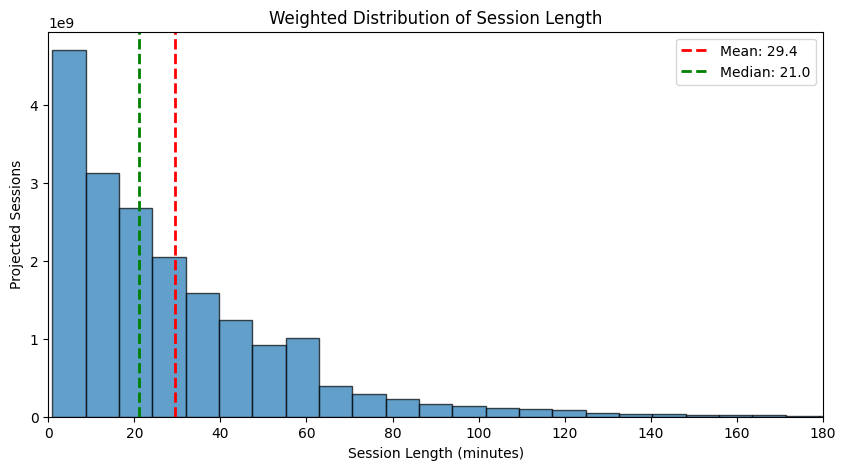

Session length, weighted mean (min): 29.4
Session length, weighted median (min): 21.0


In [37]:
# %%
v_persons['duration_min'] = (v_persons['end_ts'] - v_persons['start_ts']).dt.total_seconds() / 60

# Weighted mean
weighted_mean = (v_persons['duration_min'] * v_persons['weight']).sum() / v_persons['weight'].sum()

# Weighted median
df_sorted = v_persons.sort_values('duration_min')
cumsum = df_sorted['weight'].cumsum()
cutoff = df_sorted['weight'].sum() / 2.0
weighted_median = df_sorted[cumsum >= cutoff]['duration_min'].iloc[0]

plt.figure(figsize=(10, 5))
plt.hist(v_persons['duration_min'], bins=50, weights=v_persons['weight'], edgecolor='black', alpha=0.7)
plt.axvline(weighted_mean, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {weighted_mean:.1f}')
plt.axvline(weighted_median, color='green', linestyle='dashed', linewidth=2, label=f'Median: {weighted_median:.1f}')
plt.xlim(0, 180) # limited x-axis to 180 mins so the plot looks readable
plt.title("Weighted Distribution of Session Length")
plt.xlabel("Session Length (minutes)")
plt.ylabel("Projected Sessions")
plt.legend()
plt.show()

print("Session length, weighted mean (min):", round(weighted_mean, 1))
print("Session length, weighted median (min):", round(weighted_median, 1))

**Answer:** The mean is much higher than the median because of the right skewness. A lot of people watch for just 1-2 minutes (channel surfing), but some leave the TV on for the whole day, which makes the mean very big. It is better to show the median to the client because it reflects the typical viewing time and ignores big outliers.

### Task 2 - Program reach curve

Ratings per telecast:
   telecast_date  h_rating  p_rating  proj_aud_M
2024-10-01 18:30      3.47      1.67        5.28
2024-10-02 18:30      3.07      1.48        4.68
2024-10-03 18:30      2.99      1.47        4.68
2024-10-04 18:30      3.00      1.51        4.81
2024-10-07 18:30      3.06      1.52        4.83
2024-10-08 18:30      3.17      1.57        4.97
2024-10-09 18:30      2.98      1.48        4.70
2024-10-10 18:30      3.38      1.62        5.13
2024-10-11 18:30      3.09      1.48        4.69
2024-10-14 18:30      2.93      1.45        4.59
2024-10-15 18:30      3.07      1.52        4.82
2024-10-16 18:30      3.01      1.46        4.62
2024-10-17 18:30      3.36      1.67        5.30
2024-10-18 18:30      2.68      1.33        4.23
2024-10-21 18:30      3.11      1.54        4.89
2024-10-22 18:30      3.58      1.80        5.70
2024-10-23 18:30      3.36      1.64        5.21
2024-10-24 18:30      3.17      1.55        4.91
2024-10-25 18:30      3.38      1.66        5.2

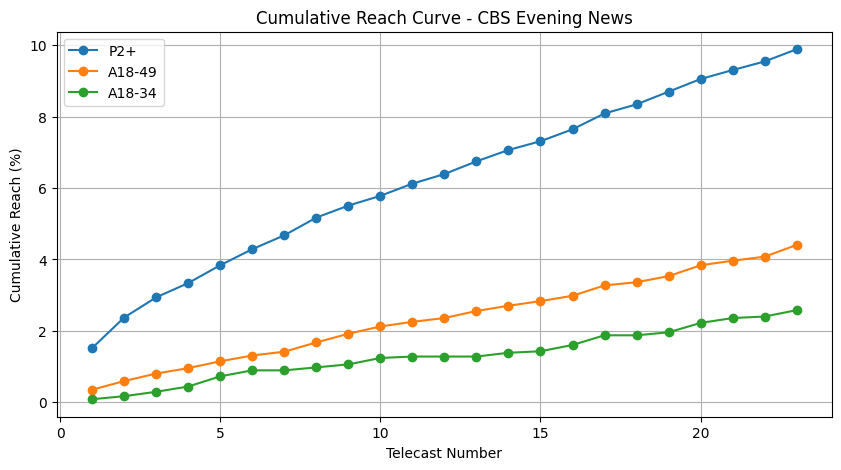

Telecasts of the program: 23
Average household rating (%): 3.2
Average P2+ rating (%): 1.6
Average projected audience (M): 4.93
Final reach P2+ (%): 9.9
Final reach A18-34 (%): 2.6
Final reach A18-49 (%): 4.4


In [38]:
# %%
# Get exact ages (code 300)
exact_ages = viewer_attributes[viewer_attributes['attr_id'] == 300].set_index('respondent_id')['value']

# Get age bands from attributes table
v_attr_full = viewer_attributes.merge(attributes, on='attr_id')
age_bands = v_attr_full[v_attr_full['attr_group'].str.contains('Age', na=False)].copy()

# Extract min and max age from labels like "18-34" or "55+"
age_bands['min_age'] = age_bands['attr_name'].str.extract(r'^(\d+)').astype(float)
age_bands['max_age'] = age_bands['attr_name'].str.extract(r'-(\d+)').astype(float)
# "55+" has no max age, so let's just put 100 to avoid NaNs
age_bands['max_age'] = age_bands['max_age'].fillna(100)

# Combine exact ages and age bands for targets
p2_exact = exact_ages[exact_ages >= 2].index.tolist()
p2_band = age_bands[age_bands['min_age'] >= 2]['respondent_id'].tolist()
p2_plus = list(set(p2_exact + p2_band))

a18_34_exact = exact_ages[(exact_ages >= 18) & (exact_ages <= 34)].index.tolist()
a18_34_band = age_bands[(age_bands['min_age'] >= 18) & (age_bands['max_age'] <= 34)]['respondent_id'].tolist()
a18_34 = list(set(a18_34_exact + a18_34_band))

a18_49_exact = exact_ages[(exact_ages >= 18) & (exact_ages <= 49)].index.tolist()
a18_49_band = age_bands[(age_bands['min_age'] >= 18) & (age_bands['max_age'] <= 49)]['respondent_id'].tolist()
a18_49 = list(set(a18_49_exact + a18_49_band))

cbs_news = programs[(programs['program_name'] == 'CBS Evening News') & 
                    (programs['network_code'] == 'CBS') & 
                    (pd.to_datetime(programs['broadcast_date']).dt.dayofweek < 5)].sort_values('start_ts')

# Average monthly weight for each person (reach rule)
monthly_avg_weights = daily_weights.groupby('respondent_id')['weight'].mean()

results = []
reached_p2 = set()
reached_1834 = set()
reached_1849 = set()

reach_p2_curve = []
reach_1834_curve = []
reach_1849_curve = []

# Reach bases (sum of average monthly weights of all in-tab for each group)
base_p2_reach = monthly_avg_weights[monthly_avg_weights.index.isin(daily_weights[daily_weights['resp_type'].isin(['R', 'L'])]['respondent_id'])].sum()
base_1834_reach = monthly_avg_weights[monthly_avg_weights.index.isin(a18_34)].sum()
base_1849_reach = monthly_avg_weights[monthly_avg_weights.index.isin(a18_49)].sum()

for _, telecast in cbs_news.iterrows():
    b_date = telecast['broadcast_date']
    t_start = telecast['start_ts']
    t_end = telecast['end_ts']
    
    # In-tab population for this day
    day_weights = daily_weights[daily_weights['broadcast_date'] == b_date].set_index('respondent_id')['weight']
    in_tab_h_day = day_weights[day_weights.index.isin(daily_weights[daily_weights['resp_type']=='H']['respondent_id'])].sum()
    in_tab_p2_day = day_weights[day_weights.index.isin(daily_weights[daily_weights['resp_type'].isin(['R', 'L'])]['respondent_id'])].sum()
    
    # Filter viewings during telecast time
    overlap = v_persons[(v_persons['network_code'] == telecast['network_code']) &
                        (v_persons['start_ts'] < t_end) & 
                        (v_persons['end_ts'] > t_start)].copy()
                        
    # Minimum 1 minute
    overlap['overlap_mins'] = (np.minimum(overlap['end_ts'], t_end) - np.maximum(overlap['start_ts'], t_start)).dt.total_seconds() / 60
    viewers = overlap[overlap['overlap_mins'] >= 1]
    
    # Household viewing
    hh_viewers = viewings[(viewings['resp_type'] == 'H') & \
                          (viewings['network_code'] == telecast['network_code']) &
                          (viewings['start_ts'] < t_end) & (viewings['end_ts'] > t_start)].copy()
    hh_viewers['overlap_mins'] = (np.minimum(hh_viewers['end_ts'], t_end) - np.maximum(hh_viewers['start_ts'], t_start)).dt.total_seconds() / 60
    h_watched = hh_viewers[hh_viewers['overlap_mins'] >= 1]['respondent_id'].unique()
    
    h_rating = day_weights.reindex(h_watched).sum() / in_tab_h_day * 100
    
    # Person viewing
    p_watched = viewers['respondent_id'].unique()
    p_rating = day_weights.reindex(p_watched).sum() / in_tab_p2_day * 100
    proj_aud = day_weights.reindex(p_watched).sum() / 1e6
    
    results.append({'telecast_date': t_start.strftime('%Y-%m-%d %H:%M'), 
                    'h_rating': round(h_rating, 2), 
                    'p_rating': round(p_rating, 2), 
                    'proj_aud_M': round(proj_aud, 2)})
    
    # Update Reach
    reached_p2.update(p_watched)
    reached_1834.update(set(p_watched).intersection(a18_34))
    reached_1849.update(set(p_watched).intersection(a18_49))
    
    reach_p2_curve.append(monthly_avg_weights.reindex(list(reached_p2)).sum() / base_p2_reach * 100)
    reach_1834_curve.append(monthly_avg_weights.reindex(list(reached_1834)).sum() / base_1834_reach * 100)
    reach_1849_curve.append(monthly_avg_weights.reindex(list(reached_1849)).sum() / base_1849_reach * 100)

ratings_df = pd.DataFrame(results)

print("Ratings per telecast:")
print(ratings_df.to_string(index=False))
print("-" * 50)

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(cbs_news) + 1), reach_p2_curve, label='P2+', marker='o')
plt.plot(range(1, len(cbs_news) + 1), reach_1849_curve, label='A18-49', marker='o')
plt.plot(range(1, len(cbs_news) + 1), reach_1834_curve, label='A18-34', marker='o')
plt.xlabel("Telecast Number")
plt.ylabel("Cumulative Reach (%)")
plt.title("Cumulative Reach Curve - CBS Evening News")
plt.legend()
plt.grid(True)
plt.show()

print("Telecasts of the program:", len(cbs_news))
print(f"Average household rating (%): {ratings_df['h_rating'].mean():.1f}")
print(f"Average P2+ rating (%): {ratings_df['p_rating'].mean():.1f}")
print(f"Average projected audience (M): {ratings_df['proj_aud_M'].mean():.2f}")
print(f"Final reach P2+ (%): {reach_p2_curve[-1]:.1f}")
print(f"Final reach A18-34 (%): {reach_1834_curve[-1]:.1f}")
print(f"Final reach A18-49 (%): {reach_1849_curve[-1]:.1f}")

**Answer:** Cumulative reach grows because each new episode brings new unique viewers. Rating stays relatively flat because it just shows the audience size for one specific moment. The P2+ audience is reached best because CBS Evening News is mostly watched by older people, so the general P2+ group fits perfectly.

### Task 3 - Program frequency

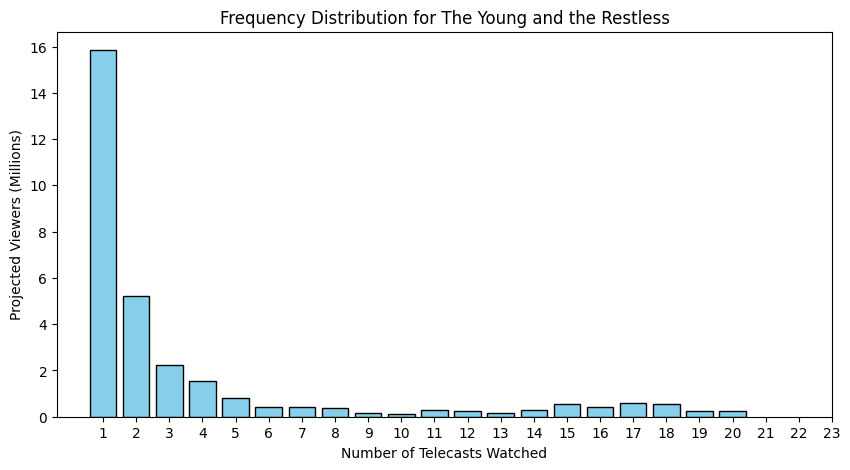

Projected viewers (M): 30.80
Average frequency (weighted): 3.6
Median frequency (weighted): 1.0
Share of views from the most loyal viewers: 0.704


In [39]:
# %%
y_r = programs[(programs['program_name'] == 'The Young and the Restless') & (programs['network_code'] == 'CBS')]

# Count viewings (min 1 min) for each respondent
yr_viewers = []
for _, telecast in y_r.iterrows():
    overlap = v_persons[(v_persons['network_code'] == telecast['network_code']) &
                        (v_persons['start_ts'] < telecast['end_ts']) & 
                        (v_persons['end_ts'] > telecast['start_ts'])].copy()
    overlap['overlap_mins'] = (np.minimum(overlap['end_ts'], telecast['end_ts']) - np.maximum(overlap['start_ts'], telecast['start_ts'])).dt.total_seconds() / 60
    watched = overlap[overlap['overlap_mins'] >= 1]['respondent_id'].unique()
    yr_viewers.extend(watched)

# Calculate frequency
freq_counts = pd.Series(yr_viewers).value_counts().reset_index()
freq_counts.columns = ['respondent_id', 'frequency']

# Join monthly weight
freq_counts = freq_counts.merge(monthly_avg_weights, on='respondent_id')

projected_viewers = freq_counts['weight'].sum() / 1e6
weighted_avg_freq = (freq_counts['frequency'] * freq_counts['weight']).sum() / freq_counts['weight'].sum()

# Weighted median
freq_sorted = freq_counts.sort_values('frequency')
cumsum_freq = freq_sorted['weight'].cumsum()
cutoff_freq = freq_sorted['weight'].sum() / 2.0
weighted_median_freq = freq_sorted[cumsum_freq >= cutoff_freq]['frequency'].iloc[0]

# Distribution plot
dist = freq_counts.groupby('frequency')['weight'].sum() / 1e6
plt.figure(figsize=(10, 5))
plt.bar(dist.index, dist.values, color='skyblue', edgecolor='black')
plt.xlabel("Number of Telecasts Watched")
plt.ylabel("Projected Viewers (Millions)")
plt.title("Frequency Distribution for The Young and the Restless")
plt.xticks(range(1, len(y_r) + 1))
plt.show()

# 80th percentile
cutoff_80 = freq_counts['weight'].sum() * 0.8
perc_80_freq = freq_sorted[cumsum_freq >= cutoff_80]['frequency'].iloc[0]

loyal_viewers = freq_counts[freq_counts['frequency'] >= perc_80_freq]
loyal_views = (loyal_viewers['frequency'] * loyal_viewers['weight']).sum()
total_views = (freq_counts['frequency'] * freq_counts['weight']).sum()
loyal_share = loyal_views / total_views

print(f"Projected viewers (M): {projected_viewers:.2f}")
print(f"Average frequency (weighted): {weighted_avg_freq:.1f}")
print(f"Median frequency (weighted): {weighted_median_freq:.1f}")
print(f"Share of views from the most loyal viewers: {loyal_share:.3f}")

**Answer:** The average frequency is a bad metric here ("the average can lie"). The distribution is U-shaped: many people watched only 1-2 times, and the loyal core watched almost all 23 episodes. The average gives us a number in the middle (3.6), but almost nobody watched exactly 3 or 4 times. So this "average viewer" simply doesn't exist.

### Task 4 - Networks by age and gender

In [40]:
# %%
# Define audiences (female/male code)
sex = v_attr_full[v_attr_full['attr_id'].isin([201, 202])].set_index('respondent_id')
males = sex[sex['attr_id'] == 201].index.tolist()
females = sex[sex['attr_id'] == 202].index.tolist()

# Define remaining age groups robustly using exact ages and age-bands
a35_54_exact = exact_ages[(exact_ages >= 35) & (exact_ages <= 54)].index.tolist()
a35_54_band = age_bands[(age_bands['min_age'] >= 35) & (age_bands['max_age'] <= 54)]['respondent_id'].tolist()
a35_54 = list(set(a35_54_exact + a35_54_band))

a55_plus_exact = exact_ages[exact_ages >= 55].index.tolist()
a55_plus_band = age_bands[age_bands['min_age'] >= 55]['respondent_id'].tolist()
a55_plus = list(set(a55_plus_exact + a55_plus_band))

targets = {
    'M18-34': set(males).intersection(a18_34),
    'W18-34': set(females).intersection(a18_34),
    'M35-54': set(males).intersection(a35_54),
    'W35-54': set(females).intersection(a35_54),
    'M55+': set(males).intersection(a55_plus),
    'W55+': set(females).intersection(a55_plus)
}

network_mins = {t: {} for t in targets}
total_mins_raw = {net: 0 for net in programs['network_code'].unique()}
youth_mins_raw = {net: 0 for net in programs['network_code'].unique()}

total_mins_w = {net: 0 for net in programs['network_code'].unique()}
youth_mins_w = {net: 0 for net in programs['network_code'].unique()}

for net, group in v_persons.groupby('network_code'):
    group_mins = group['duration_min']
    group_w_mins = group['duration_min'] * group['weight']
    
    total_mins_raw[net] = group_mins.sum()
    total_mins_w[net] = group_w_mins.sum()
    
    is_youth = group['respondent_id'].isin(a18_34)
    youth_mins_raw[net] = group_mins[is_youth].sum()
    youth_mins_w[net] = group_w_mins[is_youth].sum()
    
    for t_name, t_set in targets.items():
        is_target = group['respondent_id'].isin(t_set)
        network_mins[t_name][net] = group_w_mins[is_target].sum()

print("Top 5 Networks by Audience (Projected Minutes):")
for t_name in targets:
    top_5 = pd.Series(network_mins[t_name]).nlargest(5)
    print(f"\n{t_name}:\n{top_5}")

# Calculate shares
shares_df = pd.DataFrame({
    'Weighted_18_34_Share': {net: youth_mins_w[net] / total_mins_w[net] for net in total_mins_w},
    'Raw_18_34_Share': {net: youth_mins_raw[net] / total_mins_raw[net] for net in total_mins_raw}
})

# Format shares to 3 decimals as requested
shares_df = shares_df.round(3)

print("\n18-34 share of minutes per network:")
print(shares_df)

print("\nYoungest network:", shares_df['Weighted_18_34_Share'].idxmax())
print("Oldest network:", shares_df['Weighted_18_34_Share'].idxmin())

Top 5 Networks by Audience (Projected Minutes):

M18-34:
FOX    4.386650e+09
NBC    3.910388e+09
CBS    3.044350e+09
ABC    3.010781e+09
FX     1.473963e+09
dtype: float64

W18-34:
FOX    4.574441e+09
NBC    4.527593e+09
ABC    3.504858e+09
CBS    2.811222e+09
FX     1.383466e+09
dtype: float64

M35-54:
FOX    1.280467e+10
NBC    1.098668e+10
ABC    9.037002e+09
CBS    8.134069e+09
FX     2.370803e+09
dtype: float64

W35-54:
NBC     1.163910e+10
FOX     1.116139e+10
ABC     9.438556e+09
CBS     8.162798e+09
HGTV    3.051809e+09
dtype: float64

M55+:
CBS    3.827403e+10
NBC    3.426741e+10
FOX    3.087851e+10
ABC    3.079334e+10
FNC    2.790371e+10
dtype: float64

W55+:
CBS    4.712032e+10
NBC    4.139187e+10
ABC    3.884001e+10
FOX    3.691472e+10
FNC    3.145073e+10
dtype: float64

18-34 share of minutes per network:
       Weighted_18_34_Share  Raw_18_34_Share
ABC                   0.064            0.060
BRAVO                 0.148            0.127
CBS                   0.051        

**Answer:** The raw data shows smaller shares for young adults because it is hard to recruit people aged 18-34 to install TV meters, so the weighting system gives them higher weights to fix this. If we report raw data, we will show incorrect (too small) audiences for young people.

**Bonus answer:** If I sold ads on the oldest network (FNC) to an advertiser targeting young adults, I would pitch the "co-viewing" concept. Young people often watch TV together with their older relatives, so we can reach them in a shared viewing environment.